<a href="https://colab.research.google.com/github/anaghahegde326/BIS_LAB/blob/main/BIS_LAB6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Satellite Image Classification Completed
Number of Classes: 3


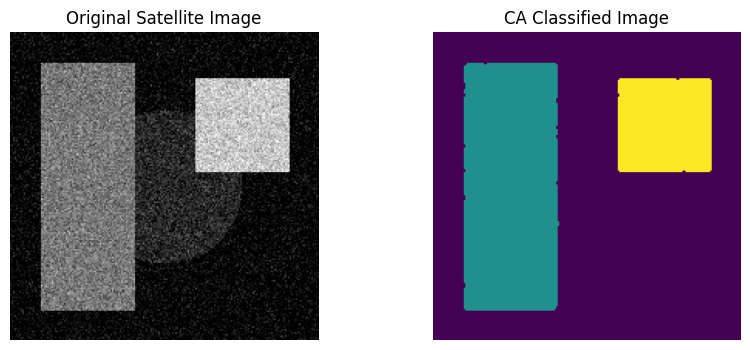

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a synthetic satellite-like grayscale image
def create_synthetic_satellite_image():
    # Generate a background with some structured gradients and noise
    np.random.seed(42)
    grid = np.zeros((200, 200), dtype=np.uint8)

    # Draw some shapes mimicking water body, forest, and urban area
    cv2.circle(grid, (100, 100), 50, 40, -1)  # Low intensity (Water)
    cv2.rectangle(grid, (20, 20), (80, 180), 120, -1)  # Medium intensity (Forest/Vegetation)
    cv2.rectangle(grid, (120, 30), (180, 90), 200, -1)  # High intensity (Urban/Buildings)

    # Add noise to simulate real satellite imagery
    noise = np.random.normal(0, 25, grid.shape).astype(np.int16)
    noisy_image = np.clip(grid.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    return noisy_image

# Save synthetic image locally as satellite.jpg
synthetic_img = create_synthetic_satellite_image()
cv2.imwrite("satellite.jpg", synthetic_img)

# Load grayscale image
img = cv2.imread("satellite.jpg", 0)

if img is None:
    raise ValueError("Image not found!")

# Initial pixel classification
labels = np.zeros(img.shape, dtype=int)
labels[img < 85] = 0
labels[(img >= 85) & (img < 170)] = 1
labels[img >= 170] = 2

# Parallel Cellular Automata
def update_cells(grid):
    new_grid = grid.copy()
    rows, cols = grid.shape

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):
            # Get neighboring cells
            neighbors = grid[i-1:i+2, j-1:j+2]
            values, counts = np.unique(
                neighbors, return_counts=True
            )
            # Majority voting
            new_grid[i, j] = values[np.argmax(counts)]

    return new_grid

# Perform iterations
iterations = 5
for _ in range(iterations):
    labels = update_cells(labels)

print("Satellite Image Classification Completed")
print("Number of Classes:", len(np.unique(labels)))

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(labels, cmap="viridis")
plt.title("CA Classified Image")
plt.axis("off")

plt.show()

Noise Removal Completed
Feature Extraction Completed


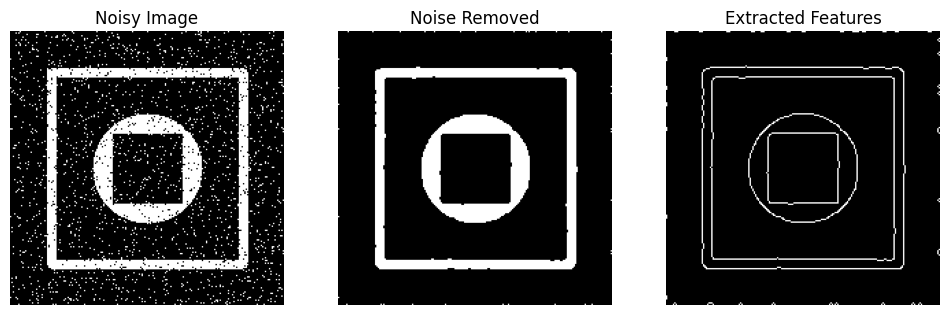

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a synthetic high-contrast pattern image
def create_synthetic_pattern():
    # Initialize a black canvas
    canvas = np.zeros((200, 200), dtype=np.uint8)
    # Draw some stark white geometric shapes (patterns)
    cv2.rectangle(canvas, (30, 30), (170, 170), 255, 5)  # Outer border
    cv2.circle(canvas, (100, 100), 40, 255, -1)         # Solid central circle
    cv2.rectangle(canvas, (75, 75), (125, 125), 0, -1)   # Inner cutout square
    return canvas

# Save the generated pattern image locally
pattern_img = create_synthetic_pattern()
cv2.imwrite("pattern.jpg", pattern_img)

# Load grayscale image
img = cv2.imread("pattern.jpg", 0)

if img is None:
    raise ValueError("Image not found!")

# Convert to binary image
_, binary = cv2.threshold(
    img, 127, 1, cv2.THRESH_BINARY
)

# Add random noise
noise = np.random.rand(*binary.shape) < 0.05
noisy = binary.copy()
noisy[noise] = 1 - noisy[noise]

# Cellular Automata noise removal
def remove_noise(grid):
    new_grid = grid.copy()
    rows, cols = grid.shape

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):
            # Count neighboring active cells
            neighbors = grid[i-1:i+2, j-1:j+2]
            count = np.sum(neighbors)

            # Majority rule
            if count >= 5:
                new_grid[i, j] = 1
            else:
                new_grid[i, j] = 0

    return new_grid

# Apply CA rules
cleaned = noisy.copy()
for _ in range(3):
    cleaned = remove_noise(cleaned)

# Feature extraction: identify boundary pixels
features = cv2.Canny(
    (cleaned * 255).astype(np.uint8),
    50, 150
)

print("Noise Removal Completed")
print("Feature Extraction Completed")

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cleaned, cmap="gray")
plt.title("Noise Removed")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(features, cmap="gray")
plt.title("Extracted Features")
plt.axis("off")

plt.show()